# S&P 500 Realized Volatility Forecasting
## Rylan Wade
## ISE-537 - Financial Analytics

This notebook summarizes the completed pipeline using saved project artifacts and does not retrain models.

## Setup And Artifact Checks

The notebook imports project code, defines compact loaders, and verifies that the saved submission artifacts exist.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config
from src import data, diagnostics, evaluate, experiment_registry, features, graphs, portfolio, regime_features

RESULTS = ROOT / "data" / "results"
FIGURES = RESULTS / "figures"
RAW = ROOT / "data" / "raw"
FEATURE_DIR = ROOT / "data" / "features"
GRAPH_DIR = ROOT / "data" / "graphs"

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def read_csv(path, **kwargs):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path, **kwargs)

def read_parquet(path, **kwargs):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_parquet(path, **kwargs)

def show_table(df, rows=10, cols=None, sort_by=None, ascending=True):
    out = df.copy()
    if sort_by and sort_by in out.columns:
        out = out.sort_values(sort_by, ascending=ascending)
    if cols:
        out = out[[c for c in cols if c in out.columns]]
    display(out.head(rows))

def show_fig(name):
    path = FIGURES / name
    if path.exists():
        display(Image(filename=str(path)))

required_artifacts = {
    "raw prices": RAW / "prices.parquet",
    "weekly realized volatility": RAW / "weekly_rv.parquet",
    "ticker universe": RAW / "tickers.json",
    "macro series": RAW / "macro_series.parquet",
    "baseline features": FEATURE_DIR / "features.parquet",
    "macro features": FEATURE_DIR / "regime_features.parquet",
    "target": FEATURE_DIR / "target.parquet",
    "splits": FEATURE_DIR / "splits.parquet",
    "sector graph": GRAPH_DIR / "sector_edges_by_year.parquet",
    "Granger graph": GRAPH_DIR / "granger_edges.parquet",
    "experiment registry": RESULTS / "experiment_registry.csv",
    "final ML metrics": RESULTS / "final_ml_metrics_table.csv",
    "final rank metrics": RESULTS / "final_rank_ic_table.csv",
    "calibration summary": RESULTS / "final_calibration_summary.csv",
    "portfolio inverse-vol": RESULTS / "final_portfolio_inverse_vol_metrics.csv",
    "portfolio long-short": RESULTS / "final_portfolio_long_short_metrics.csv",
    "portfolio vol-target": RESULTS / "final_portfolio_vol_target_metrics.csv",
    "portfolio min-var": RESULTS / "final_portfolio_minvar_metrics.csv",
}
artifact_check = pd.DataFrame(
    [{"artifact": k, "path": str(v.relative_to(ROOT)), "found": v.exists()} for k, v in required_artifacts.items()]
)
show_table(artifact_check, rows=len(artifact_check))

,artifact,path,found
0,raw prices,data\raw\prices.parquet,True
1,weekly realized volatility,data\raw\weekly_rv.parquet,True
2,ticker universe,data\raw\tickers.json,True
3,macro series,data\raw\macro_series.parquet,True
4,baseline features,data\features\features.parquet,True
5,macro features,data\features\regime_features.parquet,True
6,target,data\features\target.parquet,True
7,splits,data\features\splits.parquet,True
8,sector graph,data\graphs\sector_edges_by_year.parquet,True
9,Granger graph,data\graphs\granger_edges.parquet,True


## Data Collection And Preprocessing

The pipeline collects current S&P 500 market data, filters coverage, and builds weekly volatility targets with stock and macro features.

In [2]:
universe = read_csv(RESULTS / "universe_reproducibility.csv")
tickers = json.loads((RAW / "tickers.json").read_text()) if (RAW / "tickers.json").exists() else []
collection_summary = universe.copy()
collection_summary["ticker_file_count"] = len(tickers)
collection_summary["start_date"] = getattr(config, "START_DATE", None)
collection_summary["end_date"] = getattr(config, "END_DATE", None)
show_table(collection_summary, rows=5)

feature_files = [
    FEATURE_DIR / "features.parquet",
    FEATURE_DIR / "features_macro.parquet",
    FEATURE_DIR / "regime_features.parquet",
    FEATURE_DIR / "regime_normalization_stats.csv",
    FEATURE_DIR / "target.parquet",
    FEATURE_DIR / "splits.parquet",
]
rows = []
for path in feature_files:
    row = {"file": str(path.relative_to(ROOT)), "found": path.exists()}
    if path.suffix == ".parquet" and path.exists():
        df = read_parquet(path)
        row.update({"rows": len(df), "columns": len(df.columns)})
    elif path.suffix == ".csv" and path.exists():
        df = read_csv(path)
        row.update({"rows": len(df), "columns": len(df.columns)})
    elif path.suffix == ".json" and path.exists():
        row["keys"] = ", ".join(json.loads(path.read_text()).keys())
    rows.append(row)
show_table(pd.DataFrame(rows), rows=len(rows))

,universe_source,candidate_count,final_count,min_coverage,symbol_format,notes,ticker_file_count,start_date,end_date
0,current Wikipedia S&P 500 constituents,NaN,465,0.9500,yfinance-compatible symbols,Candidate count was not persisted by the origi...,465,None,None


,file,found,rows,columns
0,data\features\features.parquet,True,266445,12
1,data\features\features_macro.parquet,True,266445,21
2,data\features\regime_features.parquet,True,573,9
3,data\features\regime_normalization_stats.csv,True,9,5
4,data\features\target.parquet,True,572,465
5,data\features\splits.parquet,True,572,2


## Graph Building

Correlation, sector, and Granger graph artifacts capture cross-sectional volatility structure for the graph models.

,file,size_kb
0,data\graphs\granger_edges.parquet,22.1426
1,data\graphs\granger_pvalues.parquet,"2,212.9229"
2,data\graphs\granger_vol_edges.parquet,35.8838
3,data\graphs\granger_vol_pvalues.parquet,"2,212.9229"
4,data\graphs\sector_edges_by_year.parquet,75.2383


,split,num_edges,density,mean_degree,avg_abs_correlation
0,test,"36,048.8447",0.3342,155.0488,0.2469
1,train,"58,341.3141",0.5408,250.9304,0.3321
2,val,"71,595.2692",0.6637,307.9366,0.3703


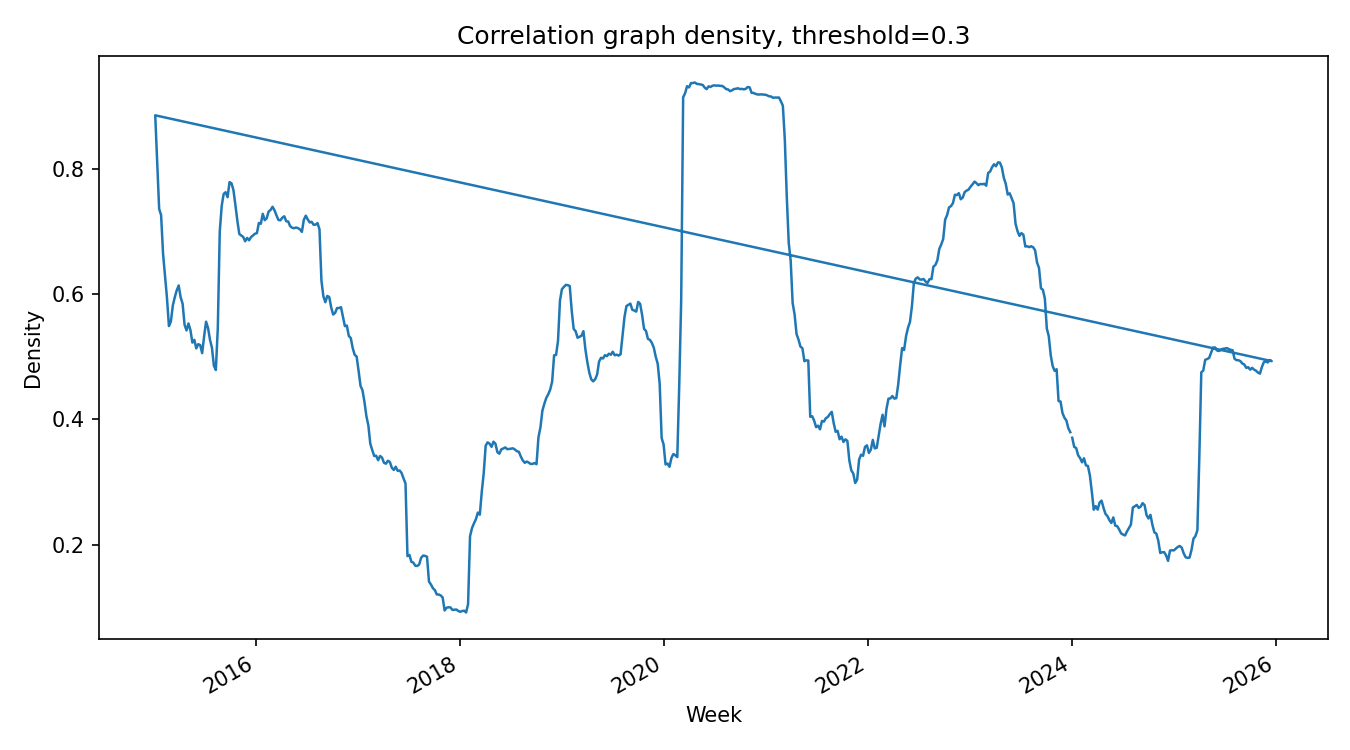

In [3]:
graph_files = sorted(GRAPH_DIR.glob("*.parquet"))
graph_summary = pd.DataFrame(
    [{"file": str(path.relative_to(ROOT)), "size_kb": path.stat().st_size / 1024} for path in graph_files[:20]]
)
show_table(graph_summary, rows=20)

density = read_csv(RESULTS / "correlation_graph_density.csv")
density_summary = density.groupby("split", dropna=False)[["num_edges", "density", "mean_degree", "avg_abs_correlation"]].mean().reset_index()
show_table(density_summary, rows=10)
show_fig("correlation_graph_density.png")

## Experiment Registry

The registry records model provenance, including feature versions, graph versions, checkpoints, predictions, and metric files.

In [4]:
registry = read_csv(RESULTS / "experiment_registry.csv")
registry_cols = [
    "experiment_id", "model_name", "model_family", "graph_type", "loss_type",
    "feature_version", "graph_version", "checkpoint_path", "prediction_path"
]
show_table(registry, rows=16, cols=registry_cols)

,experiment_id,model_name,model_family,graph_type,loss_type,feature_version,graph_version,checkpoint_path,prediction_path
0,baseline_har_per_stock,HAR per-stock,HAR,none,squared_error,har_realized_volatility_lags_v1,none,NaN,data/results/test_preds_har.parquet
1,baseline_har_pooled,HAR pooled,HAR,none,squared_error,har_realized_volatility_lags_v1,none,NaN,data/results/test_preds_har_pooled.parquet
2,baseline_lstm,LSTM,LSTM,none,mse,stock_features_v1,none,data/results/checkpoints/lstm_best.pt,data/results/test_preds_lstm.parquet
3,baseline_gnn_correlation,GNN-Correlation,GNN,correlation,mse,stock_features_v1,correlation_threshold_0.3_lookback_252,data/results/checkpoints/gnn_corr_hparam_best.pt,data/results/test_preds_gnn_corr.parquet
4,baseline_gnn_sector,GNN-Sector,GNN,sector,mse,stock_features_v1,sector_canonical_gics_labels_v1,data/results/checkpoints/gnn_sector_best.pt,data/results/test_preds_gnn_sector.parquet
5,baseline_gnn_granger,GNN-Granger,GNN,granger,mse,stock_features_v1,granger_lag_5_bonferroni,data/results/checkpoints/gnn_granger_best.pt,data/results/test_preds_gnn_granger.parquet
6,baseline_gnn_ensemble,GNN-Ensemble,GNN ensemble,correlation+sector+granger,mse,stock_features_v1,correlation+sector+granger_v1,NaN,data/results/test_preds_gnn_ensemble.parquet
7,rankloss_gnn_correlation,Rank-loss GNN-Correlation,GNN,correlation,bpr_rank,stock_features_v1,correlation_threshold_0.3_lookback_252,data/results/checkpoints/gnn_corr_rankloss_bes...,data/results/test_preds_gnn_corr_rankloss.parquet
8,rankloss_gnn_sector,Rank-loss GNN-Sector,GNN,sector,bpr_rank,stock_features_v1,sector_canonical_gics_labels_v1,data/results/checkpoints/gnn_sector_rankloss_b...,data/results/test_preds_gnn_sector_rankloss.pa...
9,rankloss_gnn_granger,Rank-loss GNN-Granger,GNN,granger,bpr_rank,stock_features_v1,granger_lag_5_bonferroni,data/results/checkpoints/gnn_granger_rankloss_...,data/results/test_preds_gnn_granger_rankloss.p...


## Baseline Models

HAR per-stock, HAR pooled, and LSTM are evaluated from saved predictions on the same test period.

In [5]:
ml = read_csv(RESULTS / "final_ml_metrics_table.csv")
rank = read_csv(RESULTS / "final_rank_ic_table.csv")
baseline_names = ["HAR per-stock", "HAR pooled", "LSTM"]
show_table(ml[ml["model"].isin(baseline_names)], rows=10, sort_by="mse")
show_table(rank[rank["model"].isin(baseline_names)], rows=10, sort_by="mean_ic", ascending=False)

,model,mse,mae,r2,da
2,LSTM,0.0324,0.1096,0.1422,0.7088
0,HAR per-stock,0.0329,0.1129,0.1307,0.7070
1,HAR pooled,0.0331,0.1133,0.1242,0.7030


,model,mean_ic,ic_ir,pct_positive,top_quartile_hit_rate,pairwise_accuracy
2,LSTM,0.4288,4.3626,1.0000,0.4990,0.6484
0,HAR per-stock,0.4049,3.4728,1.0000,0.4859,0.6407
1,HAR pooled,0.3923,3.4370,1.0000,0.4784,0.6355


## GNN Models

The graph model set includes correlation, sector, Granger, ensemble, macro-feature, and completed rank-loss variants.

In [6]:
gnn_ml = ml[ml["model"].str.contains("GNN", case=False, na=False)].copy()
gnn_rank = rank[rank["model"].isin(gnn_ml["model"])]
show_table(gnn_ml, rows=20, sort_by="mse")
show_table(gnn_rank, rows=20, sort_by="mean_ic", ascending=False)

,model,mse,mae,r2,da
9,GNN-Correlation + Macro 63d Tuned,0.0298,0.1042,0.2104,0.7217
7,GNN-Correlation + Macro Tuned,0.0309,0.1070,0.1828,0.7197
8,GNN-Correlation + Macro 21d Tuned,0.0311,0.1043,0.1771,0.7250
12,GNN-Granger + Macro,0.0314,0.1077,0.1682,0.7136
11,GNN-Sector + Macro,0.0315,0.1107,0.1664,0.7043
13,GNN-Ensemble + Macro,0.0316,0.1073,0.1640,0.7148
6,GNN-Ensemble,0.0320,0.1127,0.1531,0.7004
10,GNN-Correlation + Macro 126d Tuned,0.0321,0.1080,0.1501,0.7185
3,GNN-Correlation,0.0322,0.1076,0.1484,0.7122
4,GNN-Sector,0.0336,0.1208,0.1102,0.6822


,model,mean_ic,ic_ir,pct_positive,top_quartile_hit_rate,pairwise_accuracy
13,GNN-Ensemble + Macro,0.4378,3.9349,1.0000,0.5013,0.6528
12,GNN-Granger + Macro,0.4295,4.0642,1.0000,0.4936,0.6482
7,GNN-Correlation + Macro Tuned,0.4286,3.6803,1.0000,0.5023,0.6491
11,GNN-Sector + Macro,0.4278,3.8502,1.0000,0.4970,0.6466
9,GNN-Correlation + Macro 63d Tuned,0.4260,3.6569,1.0000,0.5021,0.6481
3,GNN-Correlation,0.4165,3.4399,1.0000,0.4919,0.6448
6,GNN-Ensemble,0.4162,3.5769,1.0000,0.4936,0.6451
10,GNN-Correlation + Macro 126d Tuned,0.4146,3.5246,1.0000,0.4901,0.6438
8,GNN-Correlation + Macro 21d Tuned,0.4120,3.9145,1.0000,0.4958,0.6429
4,GNN-Sector,0.3826,3.3994,1.0000,0.4787,0.6330


## ML Evaluation

Final point-forecast, ranking, and calibration tables summarize model accuracy and ordering quality.

,model,mse,mae,r2,da
9,GNN-Correlation + Macro 63d Tuned,0.0298,0.1042,0.2104,0.7217
7,GNN-Correlation + Macro Tuned,0.0309,0.1070,0.1828,0.7197
8,GNN-Correlation + Macro 21d Tuned,0.0311,0.1043,0.1771,0.7250
12,GNN-Granger + Macro,0.0314,0.1077,0.1682,0.7136
11,GNN-Sector + Macro,0.0315,0.1107,0.1664,0.7043
13,GNN-Ensemble + Macro,0.0316,0.1073,0.1640,0.7148
6,GNN-Ensemble,0.0320,0.1127,0.1531,0.7004
10,GNN-Correlation + Macro 126d Tuned,0.0321,0.1080,0.1501,0.7185
3,GNN-Correlation,0.0322,0.1076,0.1484,0.7122
2,LSTM,0.0324,0.1096,0.1422,0.7088


,model,mean_ic,ic_ir,pct_positive,top_quartile_hit_rate,pairwise_accuracy
13,GNN-Ensemble + Macro,0.4378,3.9349,1.0000,0.5013,0.6528
12,GNN-Granger + Macro,0.4295,4.0642,1.0000,0.4936,0.6482
2,LSTM,0.4288,4.3626,1.0000,0.4990,0.6484
7,GNN-Correlation + Macro Tuned,0.4286,3.6803,1.0000,0.5023,0.6491
11,GNN-Sector + Macro,0.4278,3.8502,1.0000,0.4970,0.6466
9,GNN-Correlation + Macro 63d Tuned,0.4260,3.6569,1.0000,0.5021,0.6481
3,GNN-Correlation,0.4165,3.4399,1.0000,0.4919,0.6448
6,GNN-Ensemble,0.4162,3.5769,1.0000,0.4936,0.6451
10,GNN-Correlation + Macro 126d Tuned,0.4146,3.5246,1.0000,0.4901,0.6438
8,GNN-Correlation + Macro 21d Tuned,0.4120,3.9145,1.0000,0.4958,0.6429


,model,calibration_slope,pearson_corr,prediction_mean,prediction_std,avg_weekly_prediction_spread_p90_p10
9,GNN-Correlation + Macro 63d Tuned,1.0298,0.4675,0.2355,0.0883,0.1431
7,GNN-Correlation + Macro Tuned,0.7678,0.4495,0.2475,0.1138,0.1644
8,GNN-Correlation + Macro 21d Tuned,0.9069,0.4419,0.2281,0.0947,0.1286
12,GNN-Granger + Macro,1.4781,0.4377,0.2417,0.0576,0.1030
10,GNN-Correlation + Macro 126d Tuned,0.7004,0.4343,0.2406,0.1205,0.1644
13,GNN-Ensemble + Macro,1.4406,0.4329,0.2380,0.0584,0.1009
11,GNN-Sector + Macro,1.0260,0.4089,0.2478,0.0775,0.1225
3,GNN-Correlation,1.1827,0.4007,0.2350,0.0659,0.1325
6,GNN-Ensemble,1.1581,0.3964,0.2594,0.0665,0.1410
0,HAR per-stock,0.7452,0.3847,0.2538,0.1004,0.2017


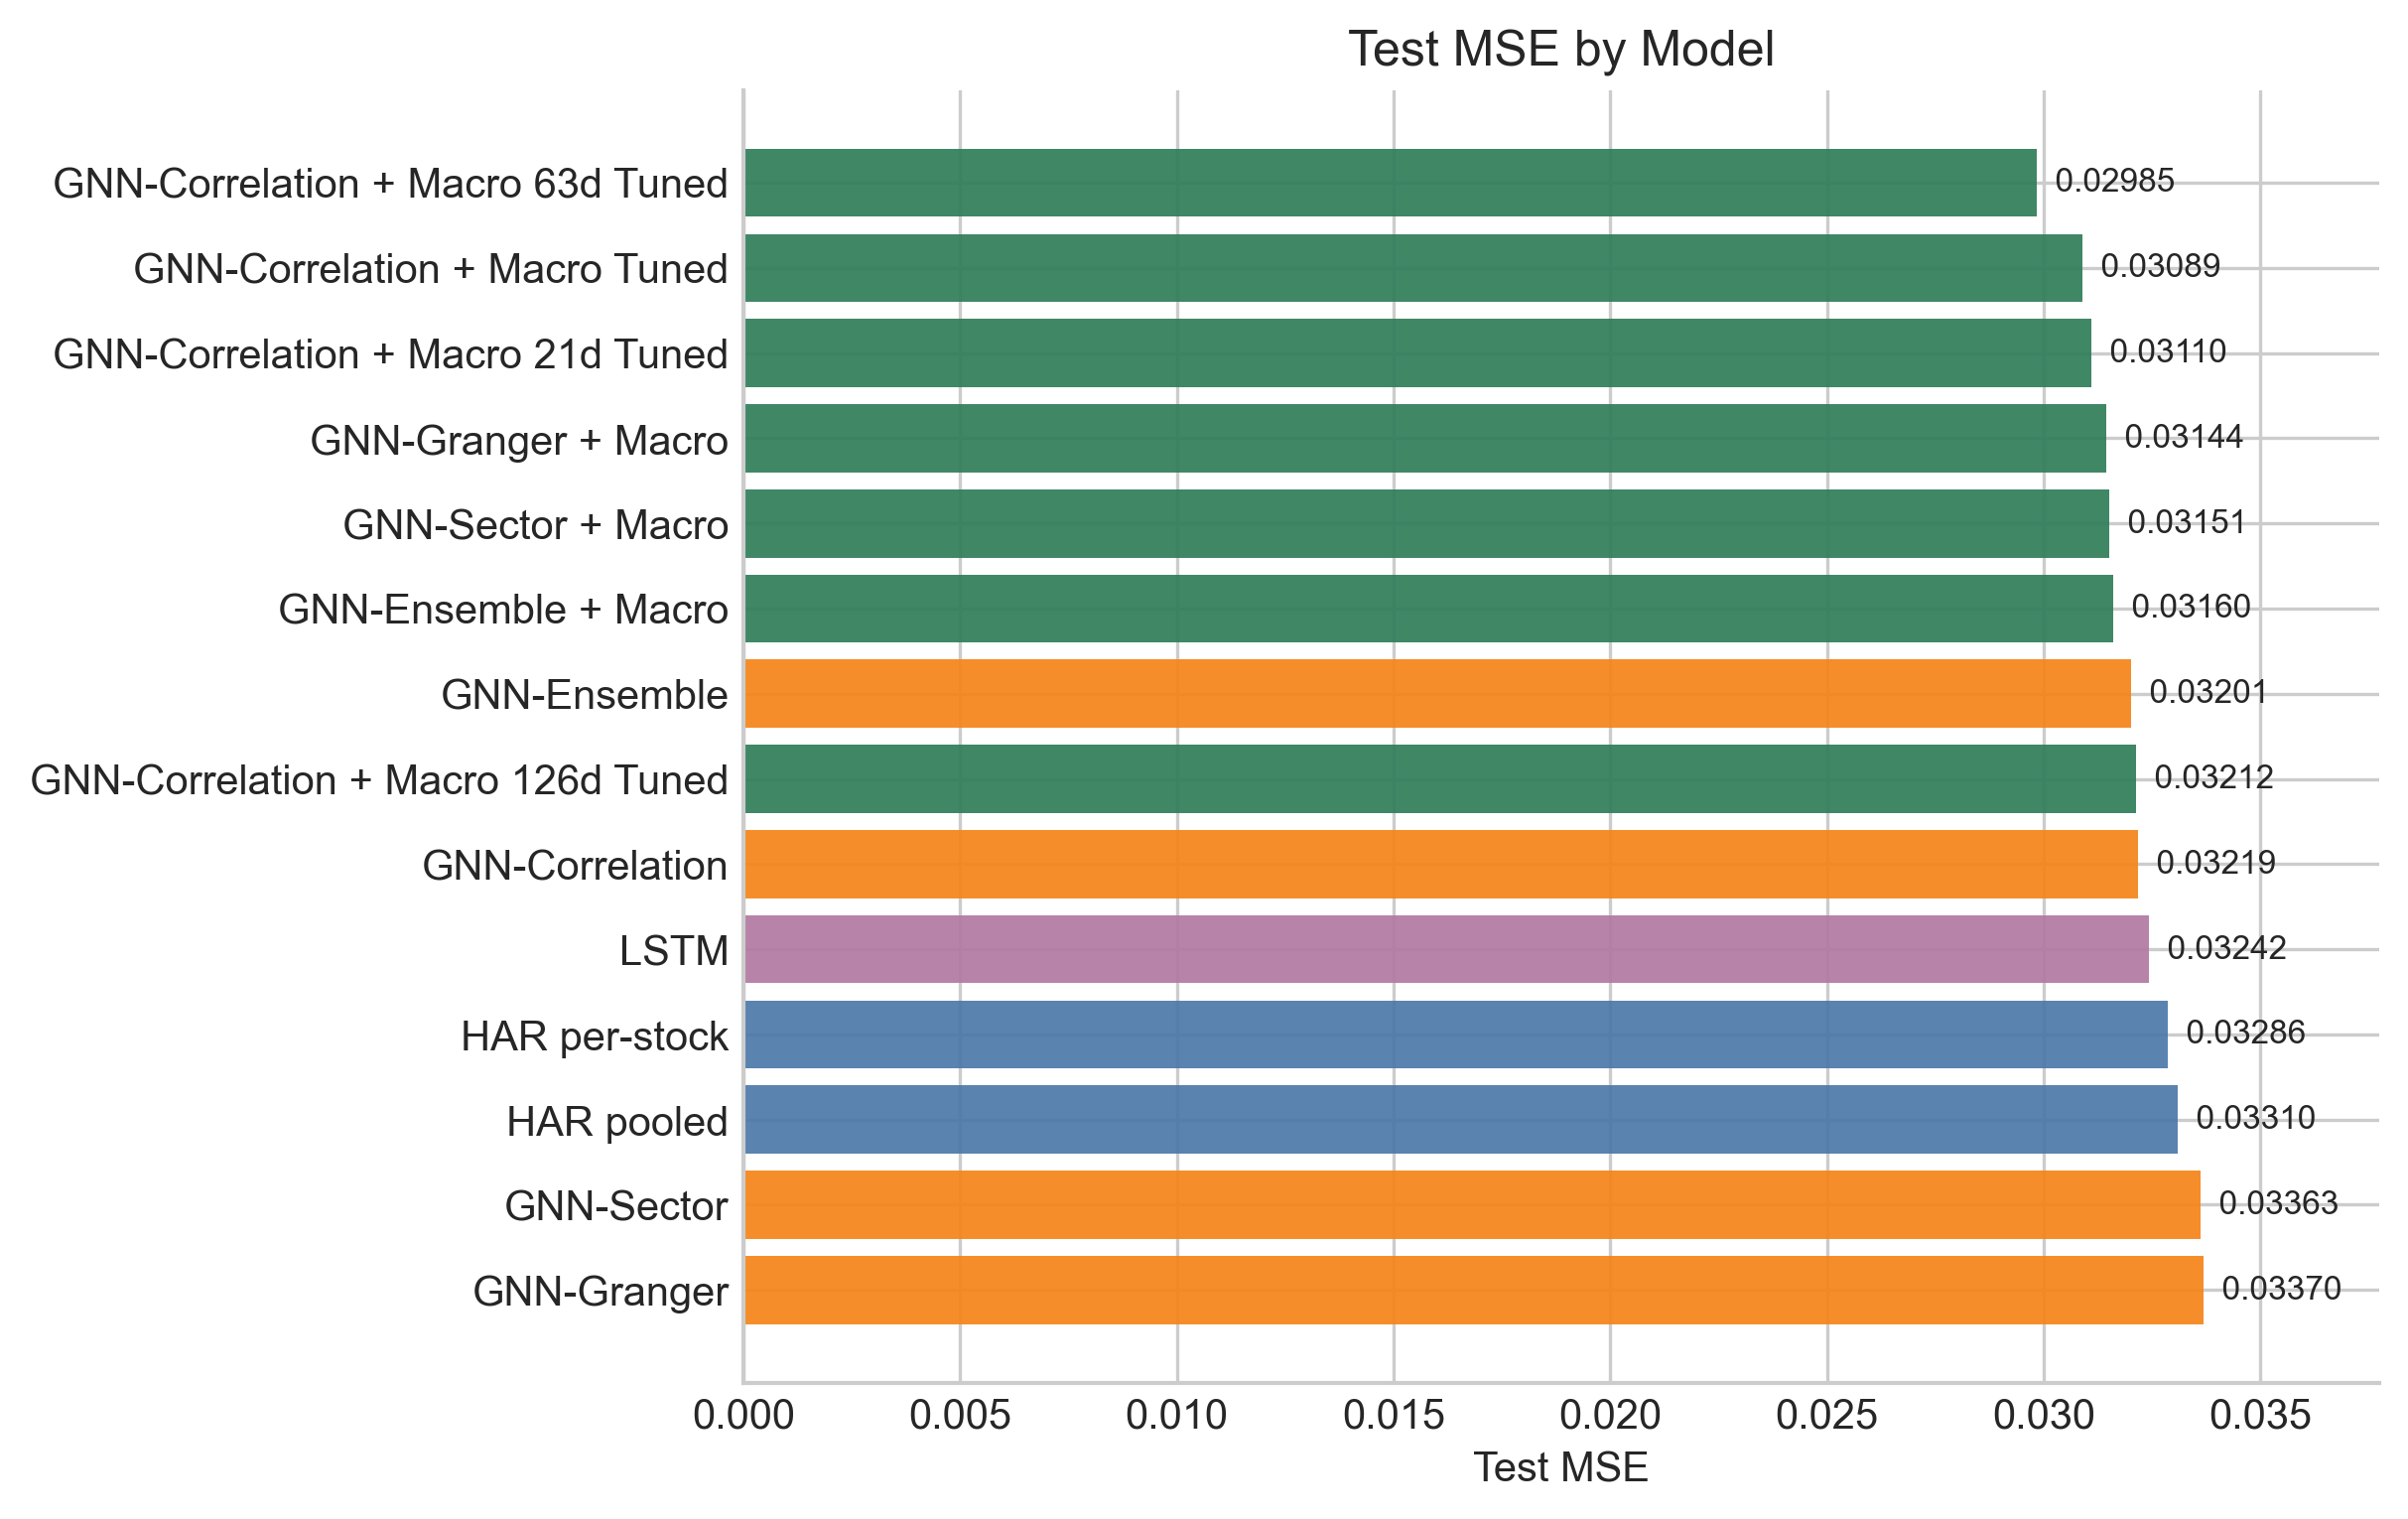

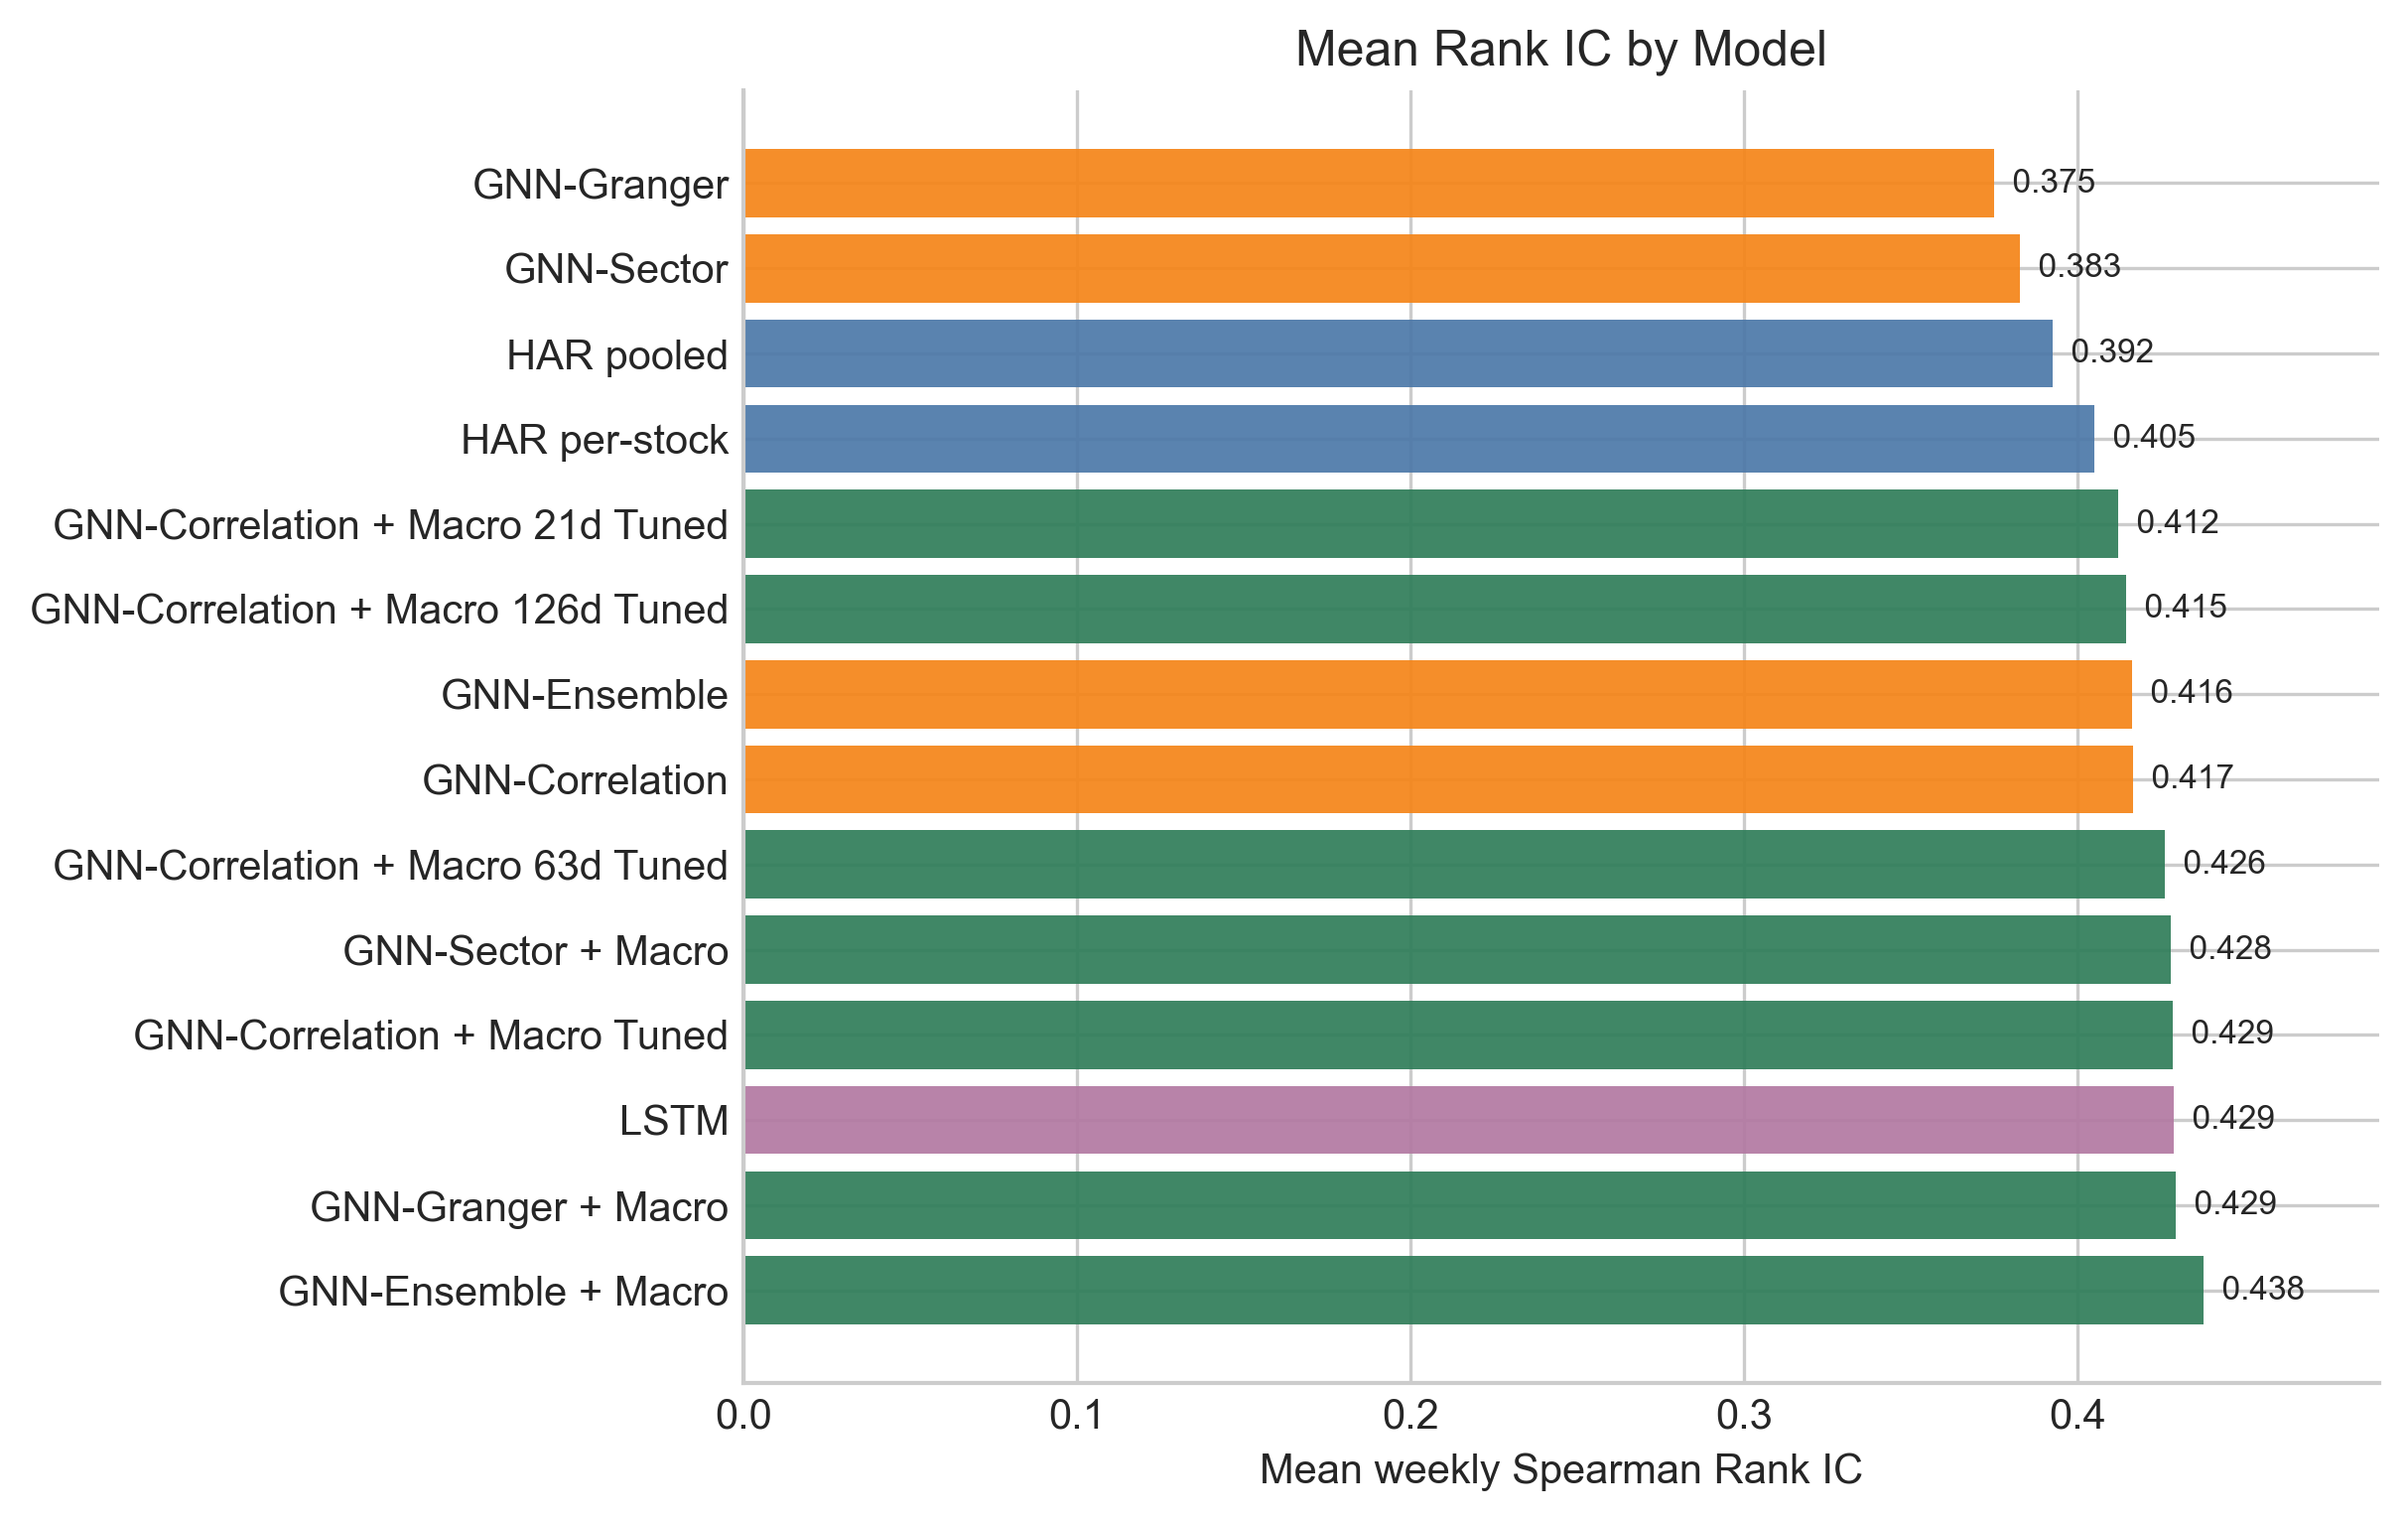

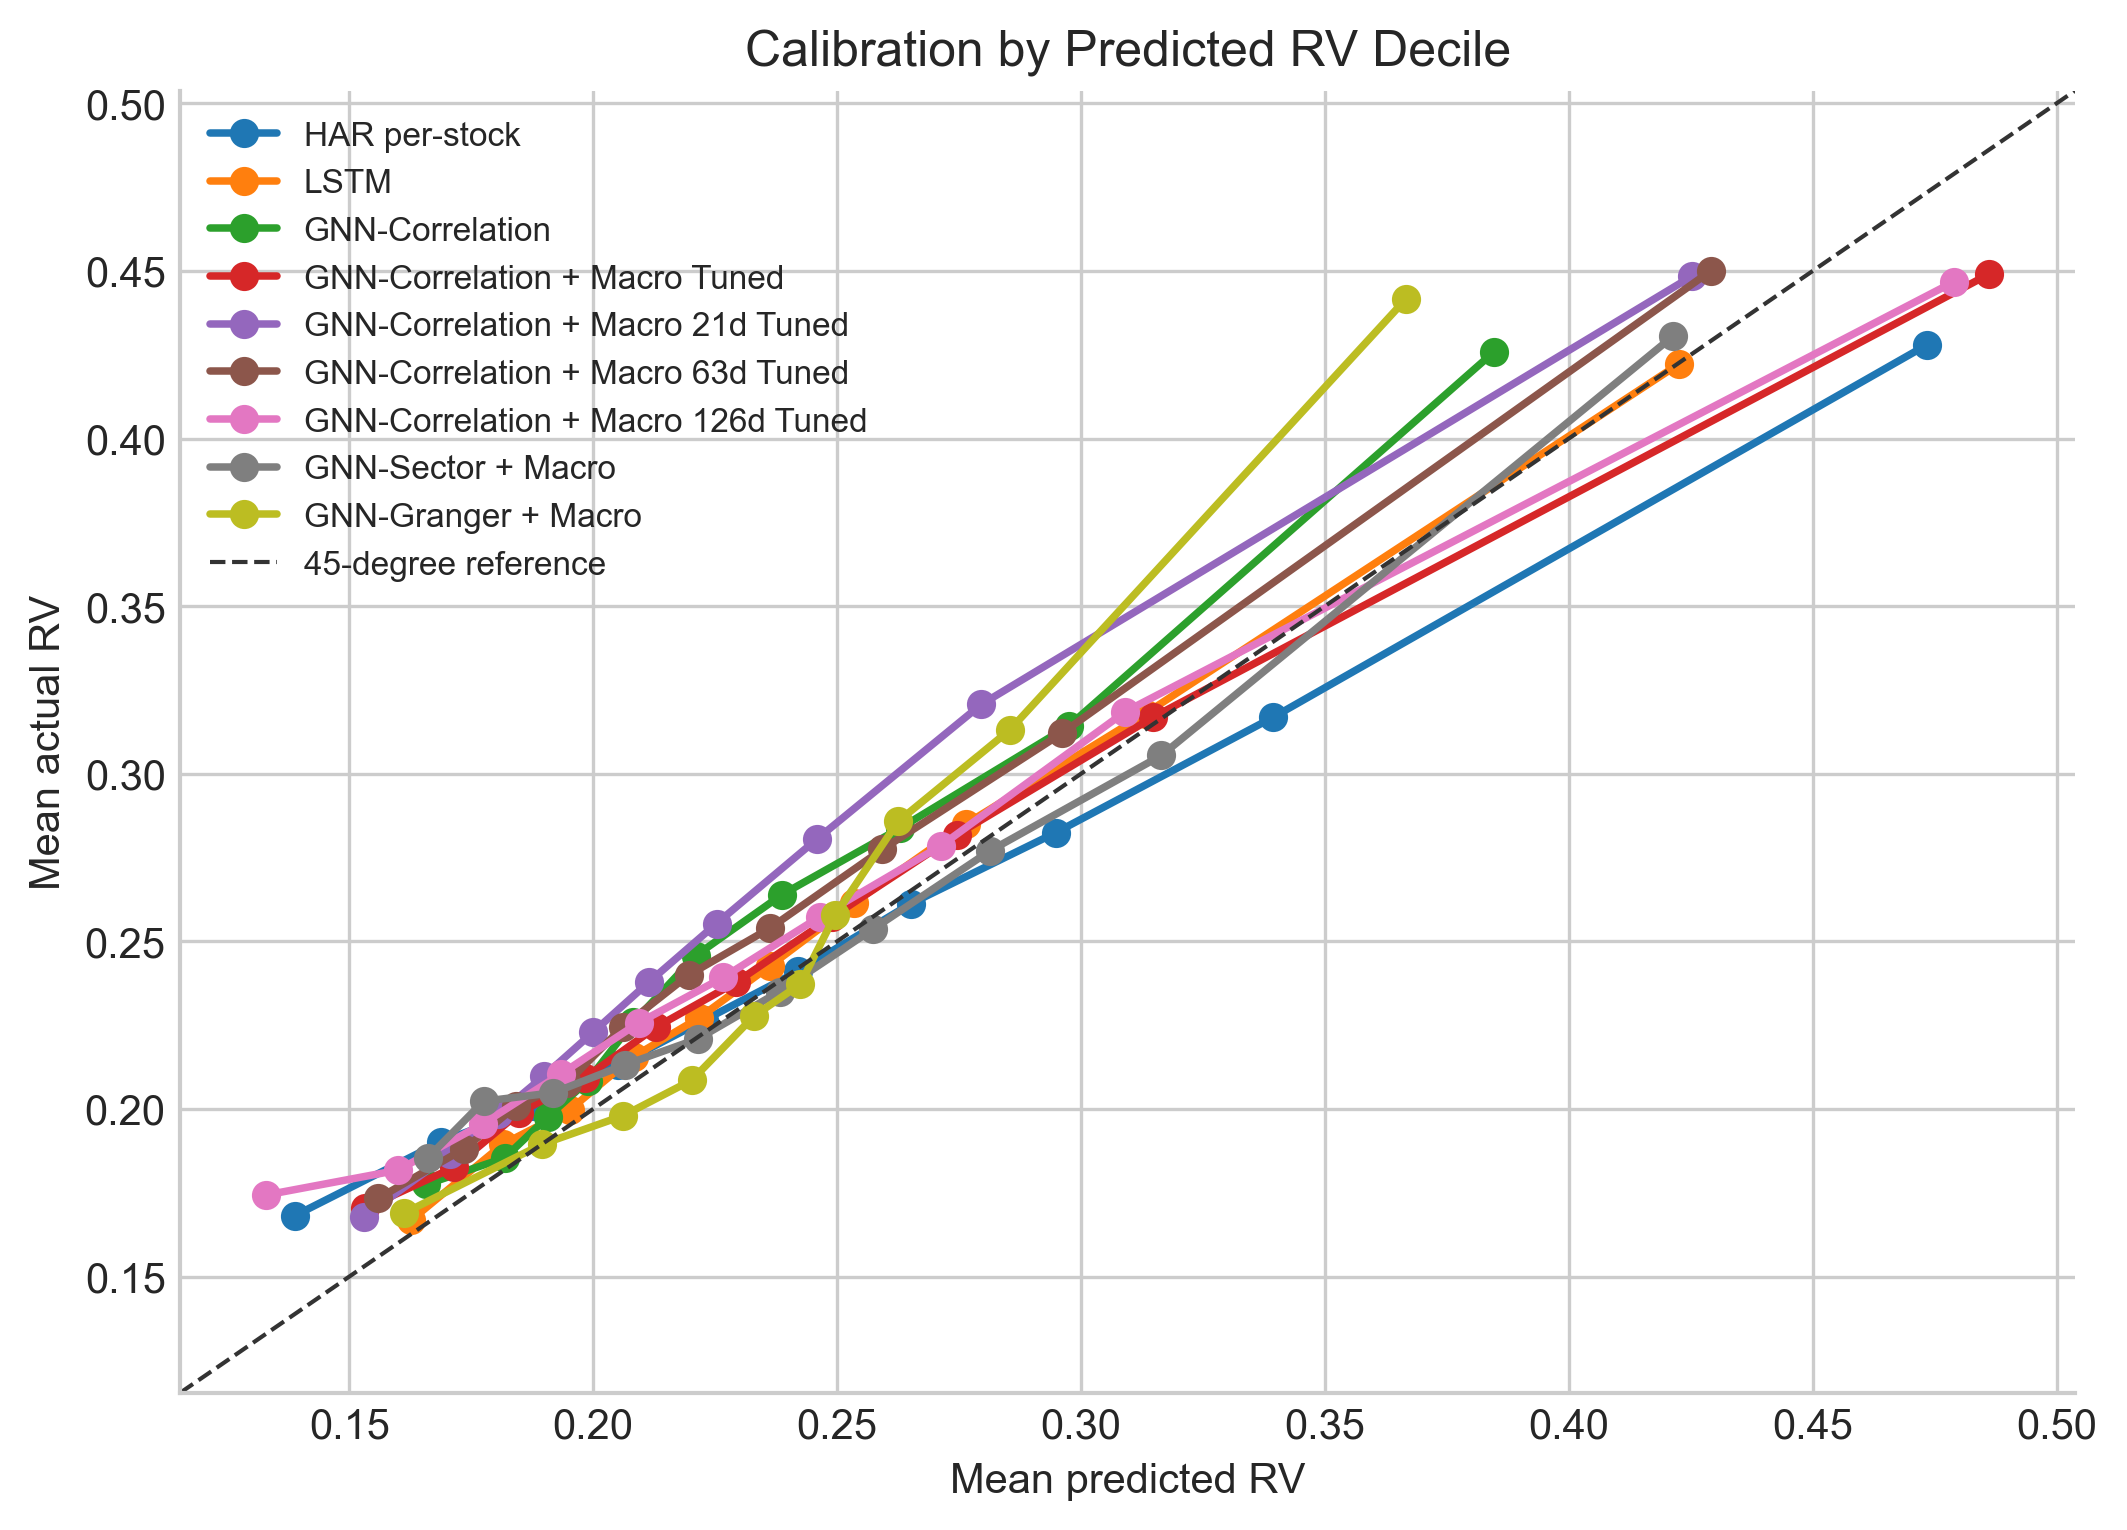

In [7]:
calibration = read_csv(RESULTS / "final_calibration_summary.csv")
show_table(ml, rows=20, sort_by="mse")
show_table(rank, rows=20, sort_by="mean_ic", ascending=False)
show_table(
    calibration,
    rows=20,
    cols=["model", "calibration_slope", "pearson_corr", "prediction_mean", "prediction_std", "avg_weekly_prediction_spread_p90_p10"],
    sort_by="pearson_corr",
    ascending=False,
)
show_fig("final_test_mse_by_model.png")
show_fig("final_rank_ic_by_model.png")
show_fig("final_calibration_by_predicted_rv.png")

## Diagnostics And Macro Features

Saved diagnostics and macro-feature comparisons show how graph value changes with calibration, regime, and feature context.

,diagnostic,found,path,rows,columns
0,prediction spread,True,data\results\prediction_spread_by_week.csv,2472,5
1,regime breakdown,True,data\results\regime_breakdown_metrics.csv,192,11
2,oversmoothing,True,data\results\oversmoothing_audit.csv,70,10
3,within-sector rank IC,True,data\results\within_sector_rank_ic_table.csv,24,4


final_macro_vs_baseline_deltas.csv


,delta_source,strategy,baseline_model,macro_model,delta_mse,delta_mae,delta_r2,delta_da,delta_ann_return,delta_sharpe
0,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro,0.0012,-0.0003,-0.0315,0.0042,NaN,NaN
1,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro 126d Tuned,-0.0001,0.0003,0.0018,0.0063,NaN,NaN
2,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro 21d Tuned,-0.0011,-0.0034,0.0288,0.0127,NaN,NaN
3,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro 63d Tuned,-0.0023,-0.0035,0.0620,0.0095,NaN,NaN
4,ML,ml_metrics,GNN-Correlation,GNN-Correlation + Macro Tuned,-0.0013,-0.0006,0.0344,0.0075,NaN,NaN
5,ML,ml_metrics,GNN-Ensemble,GNN-Ensemble + Macro,-0.0004,-0.0054,0.0109,0.0144,NaN,NaN
6,ML,ml_metrics,GNN-Granger,GNN-Granger + Macro,-0.0023,-0.0113,0.0599,0.0257,NaN,NaN
7,ML,ml_metrics,GNN-Sector,GNN-Sector + Macro,-0.0021,-0.0102,0.0562,0.0220,NaN,NaN
8,ML,ml_metrics,LSTM,LSTM + Macro,0.0024,0.0152,-0.0640,-0.0352,NaN,NaN
9,Portfolio,inverse_vol,GNN-Correlation,GNN-Correlation + Macro,NaN,NaN,NaN,NaN,0.0102,0.0722


macro_ml_metric_deltas.csv


,baseline_model,macro_model,baseline_mse,macro_mse,delta_mse,baseline_mae,macro_mae,delta_mae,baseline_r2,macro_r2,delta_r2,baseline_da,macro_da,delta_da
0,LSTM,LSTM + Macro,0.0324,0.0348,0.0024,0.1096,0.1247,0.0152,0.1422,0.0781,-0.0640,0.7088,0.6736,-0.0352
1,GNN-Correlation,GNN-Correlation + Macro,0.0322,0.0334,0.0012,0.1076,0.1073,-0.0003,0.1484,0.1168,-0.0315,0.7122,0.7164,0.0042
2,GNN-Correlation,GNN-Correlation + Macro Tuned,0.0322,0.0309,-0.0013,0.1076,0.1070,-0.0006,0.1484,0.1828,0.0344,0.7122,0.7197,0.0075
3,GNN-Correlation,GNN-Correlation + Macro 21d Tuned,0.0322,0.0311,-0.0011,0.1076,0.1043,-0.0034,0.1484,0.1771,0.0288,0.7122,0.7250,0.0127
4,GNN-Correlation,GNN-Correlation + Macro 63d Tuned,0.0322,0.0298,-0.0023,0.1076,0.1042,-0.0035,0.1484,0.2104,0.0620,0.7122,0.7217,0.0095
5,GNN-Correlation,GNN-Correlation + Macro 126d Tuned,0.0322,0.0321,-0.0001,0.1076,0.1080,0.0003,0.1484,0.1501,0.0018,0.7122,0.7185,0.0063
6,GNN-Sector,GNN-Sector + Macro,0.0336,0.0315,-0.0021,0.1208,0.1107,-0.0102,0.1102,0.1664,0.0562,0.6822,0.7043,0.0220
7,GNN-Granger,GNN-Granger + Macro,0.0337,0.0314,-0.0023,0.1190,0.1077,-0.0113,0.1084,0.1682,0.0599,0.6879,0.7136,0.0257
8,GNN-Ensemble,GNN-Ensemble + Macro,0.0320,0.0316,-0.0004,0.1127,0.1073,-0.0054,0.1531,0.1640,0.0109,0.7004,0.7148,0.0144


macro_rank_ic_deltas.csv


,baseline_model,macro_model,baseline_mean_ic,macro_mean_ic,delta_mean_ic,baseline_ic_ir,macro_ic_ir,delta_ic_ir,baseline_top_quartile_hit_rate,macro_top_quartile_hit_rate,delta_top_quartile_hit_rate,baseline_pairwise_accuracy,macro_pairwise_accuracy,delta_pairwise_accuracy
0,LSTM,LSTM + Macro,0.4288,0.4470,0.0182,4.3626,4.2167,-0.1459,0.4990,0.5074,0.0084,0.6484,0.6550,0.0066
1,GNN-Correlation,GNN-Correlation + Macro,0.4165,0.4316,0.0151,3.4399,3.8650,0.4251,0.4919,0.4938,0.0019,0.6448,0.6423,-0.0026
2,GNN-Correlation,GNN-Correlation + Macro Tuned,0.4165,0.4286,0.0121,3.4399,3.6803,0.2403,0.4919,0.5023,0.0104,0.6448,0.6491,0.0042
3,GNN-Correlation,GNN-Correlation + Macro 21d Tuned,0.4165,0.4120,-0.0045,3.4399,3.9145,0.4746,0.4919,0.4958,0.0039,0.6448,0.6429,-0.0019
4,GNN-Correlation,GNN-Correlation + Macro 63d Tuned,0.4165,0.4260,0.0095,3.4399,3.6569,0.2169,0.4919,0.5021,0.0102,0.6448,0.6481,0.0032
5,GNN-Correlation,GNN-Correlation + Macro 126d Tuned,0.4165,0.4146,-0.0019,3.4399,3.5246,0.0847,0.4919,0.4901,-0.0018,0.6448,0.6438,-0.0010
6,GNN-Sector,GNN-Sector + Macro,0.3826,0.4278,0.0452,3.3994,3.8502,0.4508,0.4787,0.4970,0.0183,0.6330,0.6466,0.0135
7,GNN-Granger,GNN-Granger + Macro,0.3749,0.4295,0.0545,3.6630,4.0642,0.4012,0.4726,0.4936,0.0209,0.6293,0.6482,0.0189
8,GNN-Ensemble,GNN-Ensemble + Macro,0.4162,0.4378,0.0216,3.5769,3.9349,0.3580,0.4936,0.5013,0.0076,0.6451,0.6528,0.0077


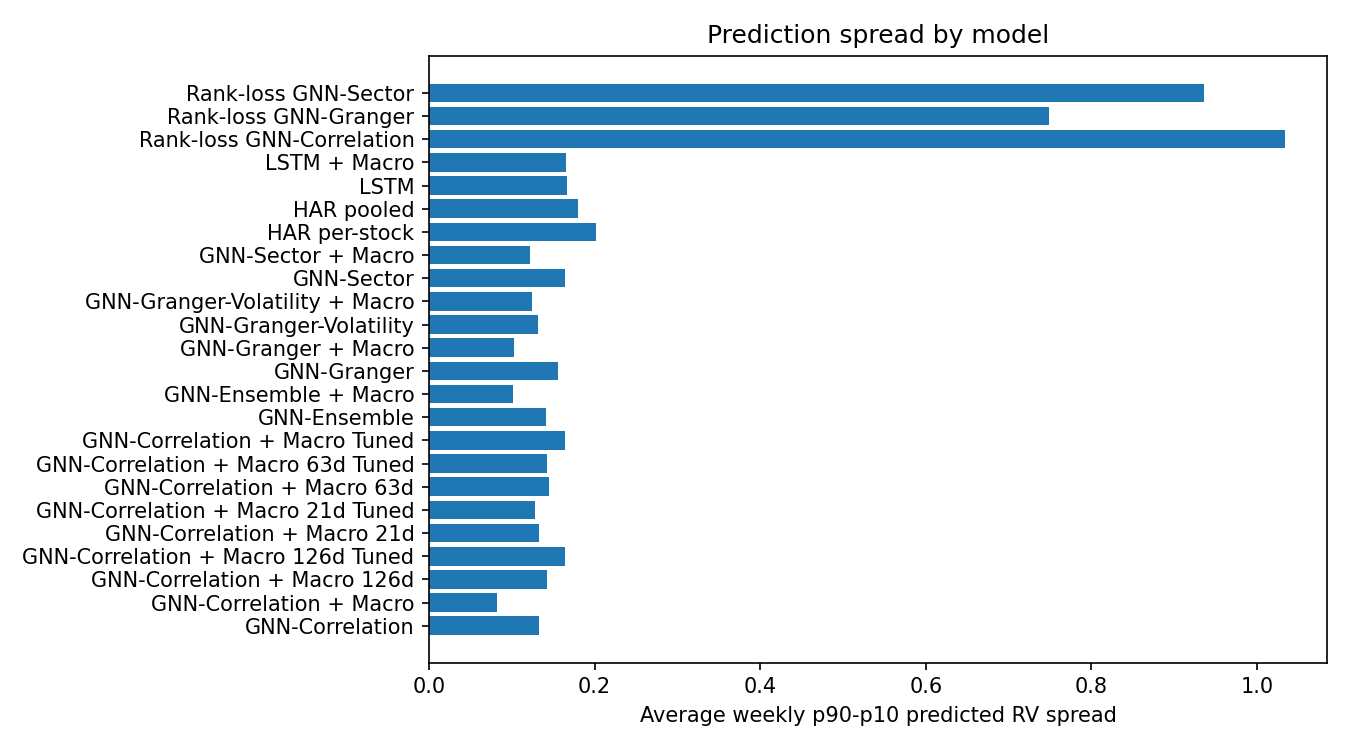

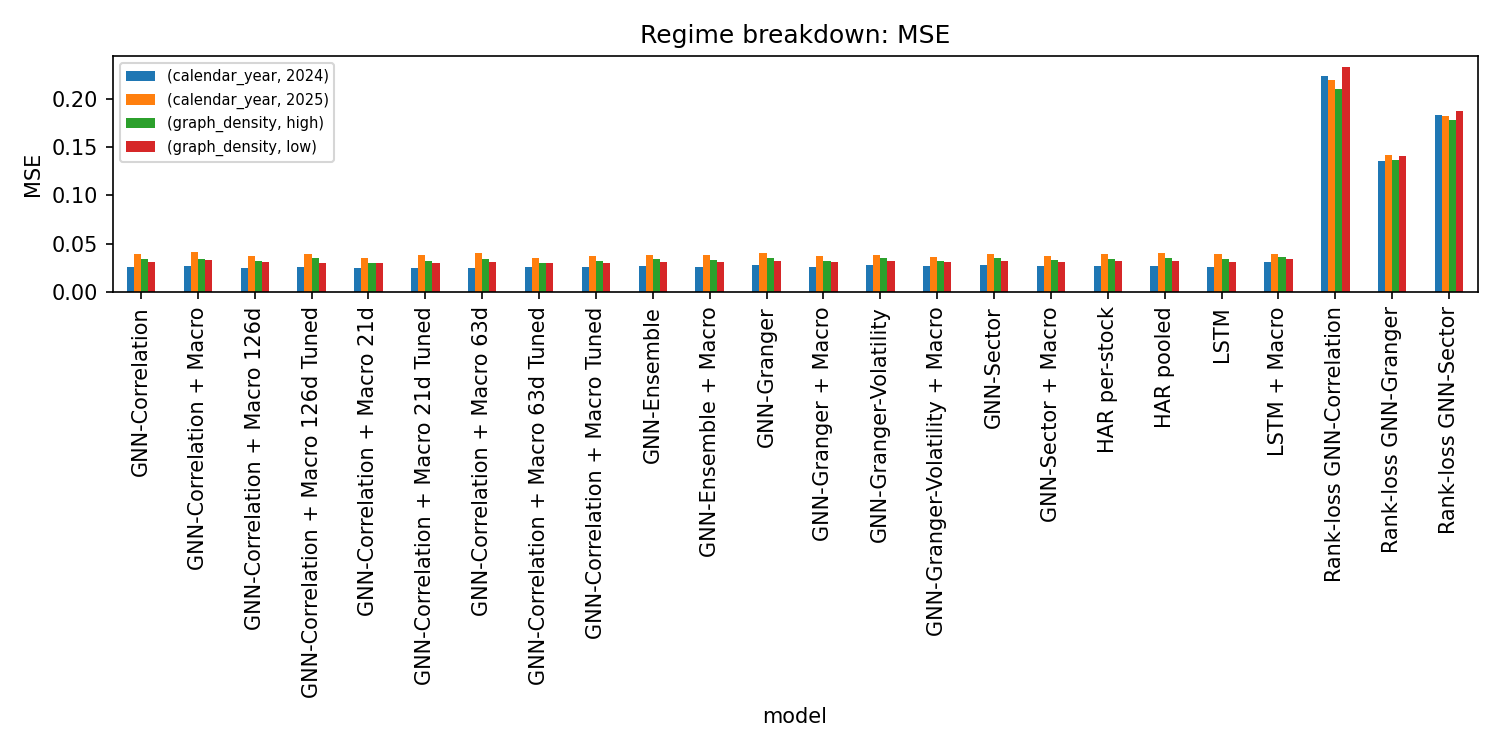

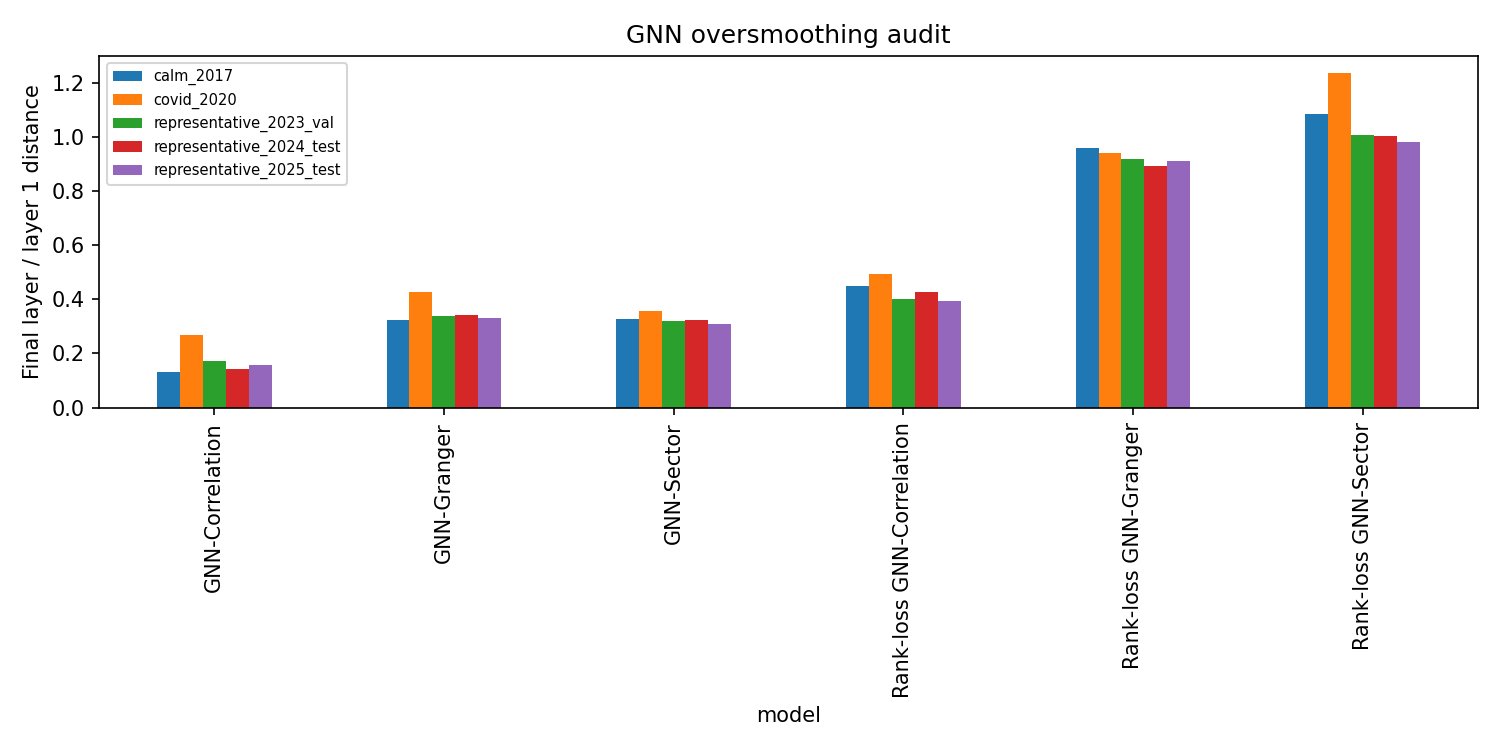

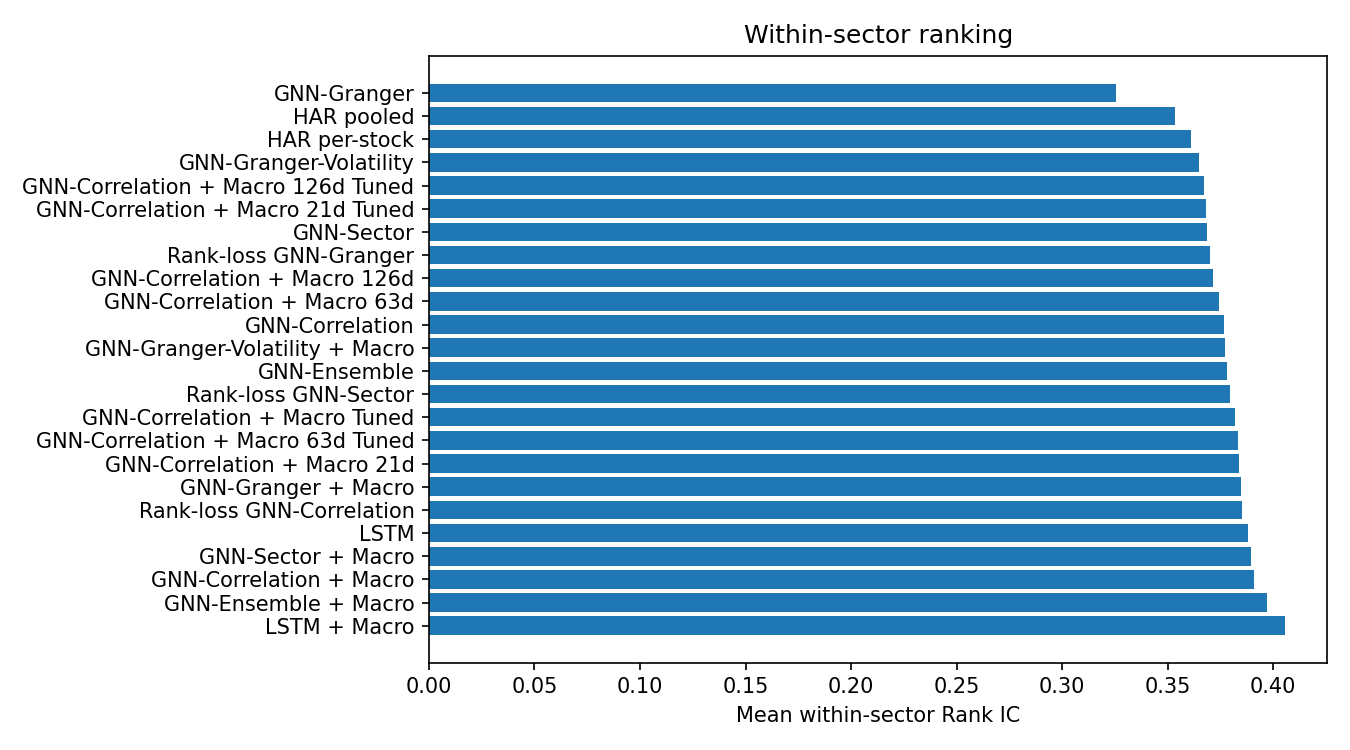

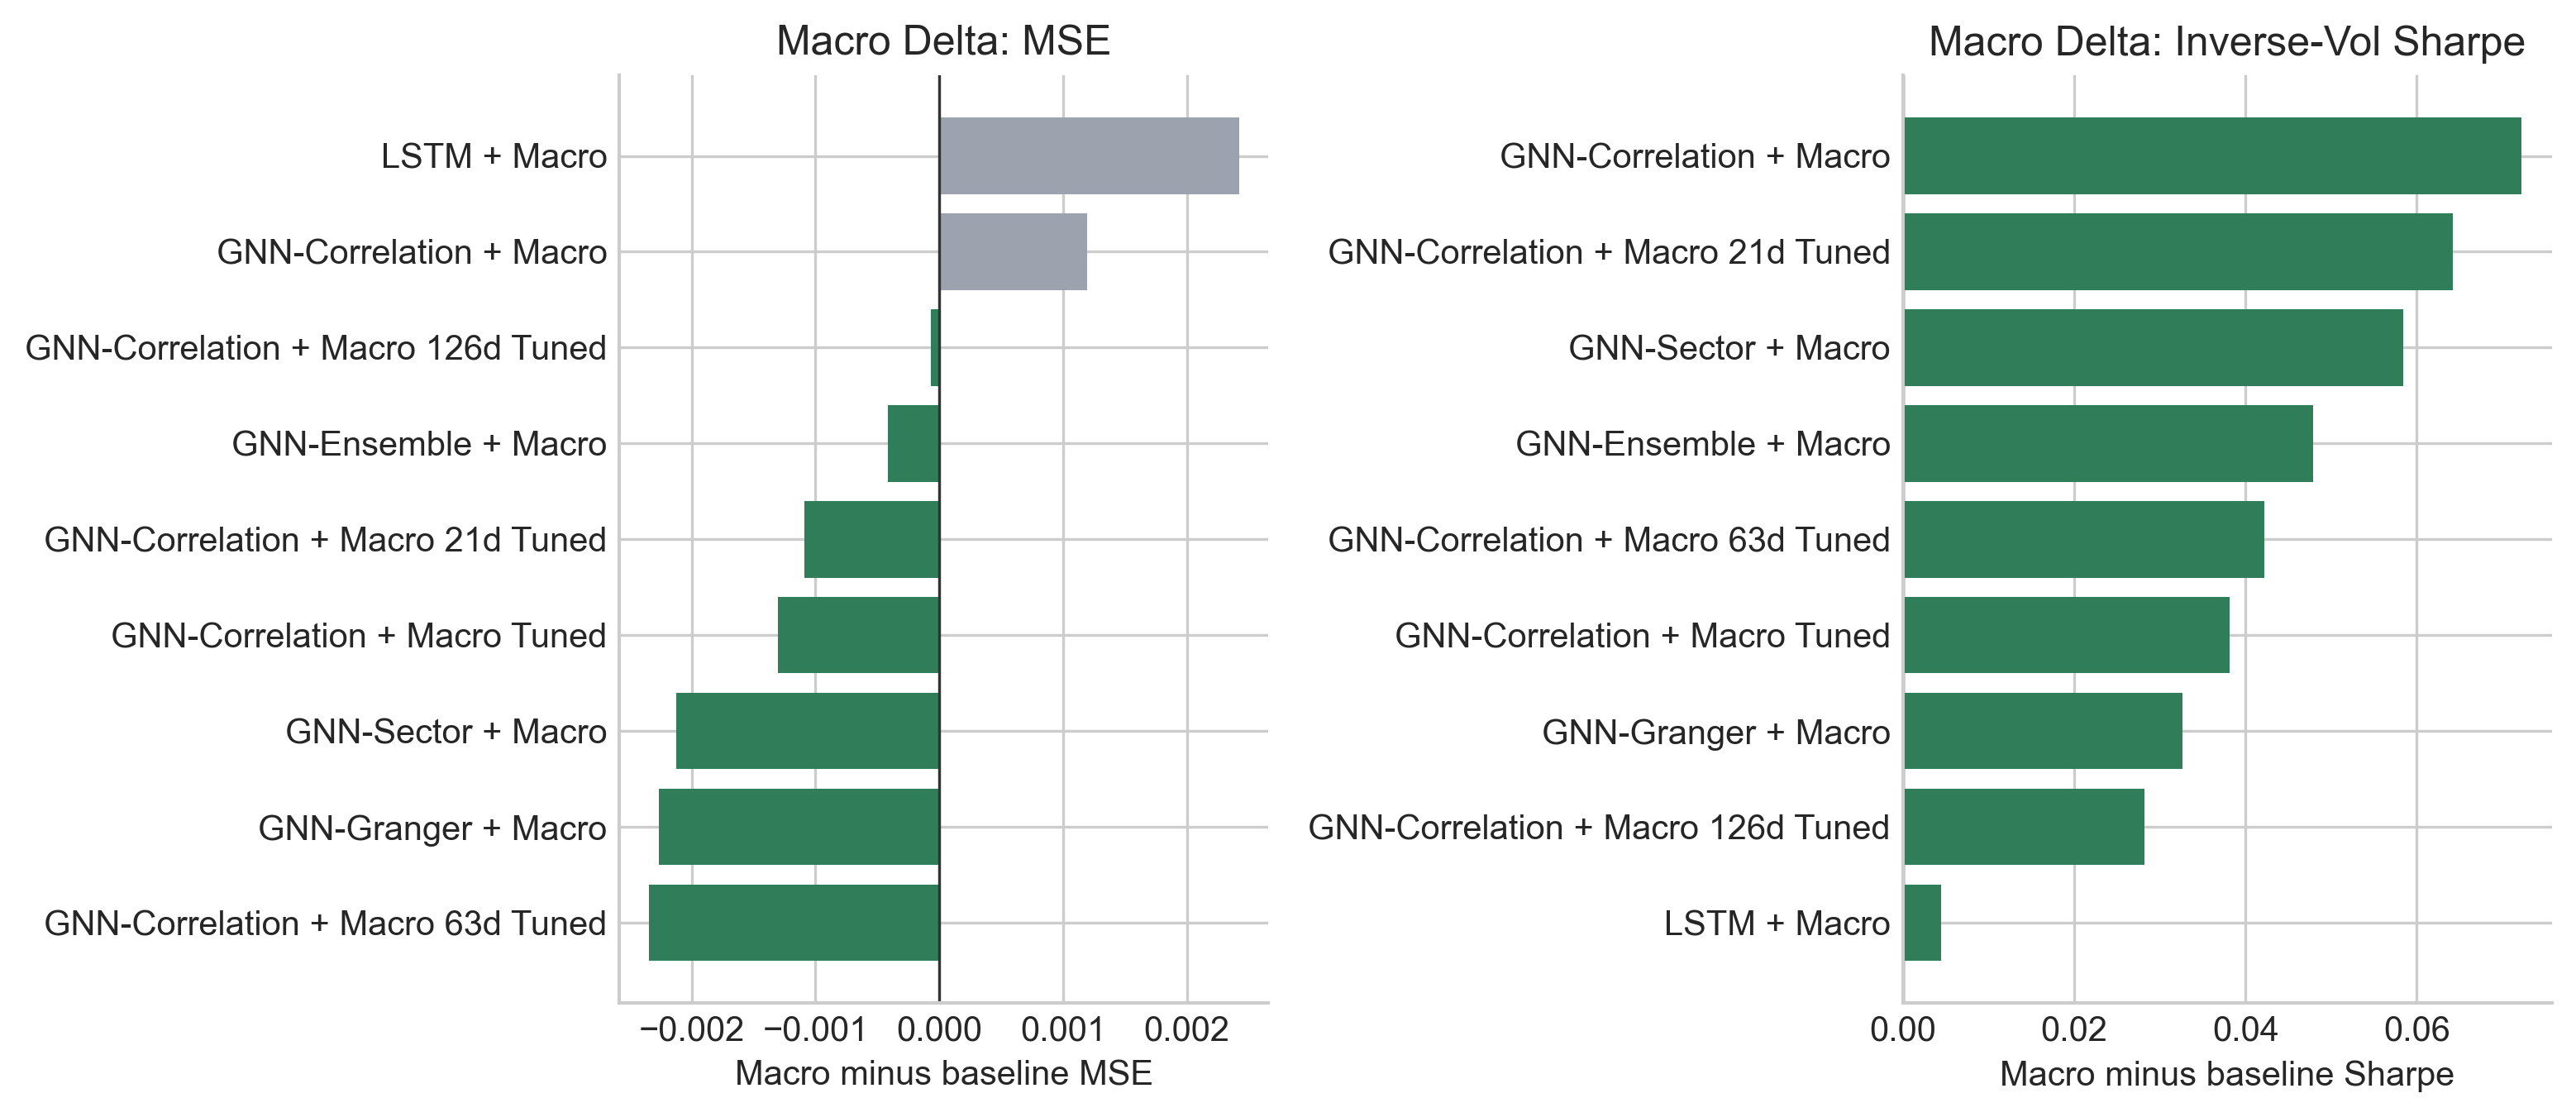

In [8]:
diagnostic_files = {
    "prediction spread": RESULTS / "prediction_spread_by_week.csv",
    "regime breakdown": RESULTS / "regime_breakdown_metrics.csv",
    "oversmoothing": RESULTS / "oversmoothing_audit.csv",
    "within-sector rank IC": RESULTS / "within_sector_rank_ic_table.csv",
}
diagnostic_summary = []
for name, path in diagnostic_files.items():
    row = {"diagnostic": name, "found": path.exists(), "path": str(path.relative_to(ROOT))}
    if path.exists():
        df = read_csv(path)
        row.update({"rows": len(df), "columns": len(df.columns)})
    diagnostic_summary.append(row)
show_table(pd.DataFrame(diagnostic_summary), rows=10)

for path in [RESULTS / "final_macro_vs_baseline_deltas.csv", RESULTS / "macro_ml_metric_deltas.csv", RESULTS / "macro_rank_ic_deltas.csv"]:
    if path.exists():
        print(path.name)
        show_table(read_csv(path), rows=12)

for fig_name in [
    "prediction_spread_by_week.png",
    "regime_breakdown_mse.png",
    "oversmoothing_audit.png",
    "within_sector_rank_ic.png",
    "final_macro_vs_baseline_deltas.png",
]:
    show_fig(fig_name)

## Portfolio Evaluation

Portfolio results test whether volatility forecasts improve inverse-volatility, long-short, volatility-targeted, and minimum-variance strategies.

Inverse volatility


,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_single_stock_weight
14,Equal-weight,0.1203,0.1370,0.5132,-0.1707,0.0000,0.0022
11,GNN-Sector + Macro,0.1103,0.1289,0.4681,-0.1594,0.0504,0.0034
13,GNN-Ensemble + Macro,0.1103,0.1299,0.4647,-0.1610,0.0372,0.0032
12,GNN-Granger + Macro,0.1097,0.1308,0.4561,-0.1639,0.0526,0.0047
8,GNN-Correlation + Macro 21d Tuned,0.1077,0.1279,0.4511,-0.1562,0.0913,0.0050
9,GNN-Correlation + Macro 63d Tuned,0.1041,0.1260,0.4292,-0.1538,0.0781,0.0068
7,GNN-Correlation + Macro Tuned,0.1031,0.1249,0.4251,-0.1510,0.0902,0.0081
5,GNN-Granger,0.1046,0.1290,0.4234,-0.1604,0.0818,0.0039
6,GNN-Ensemble,0.1035,0.1283,0.4168,-0.1586,0.0581,0.0040
10,GNN-Correlation + Macro 126d Tuned,0.1022,0.1257,0.4152,-0.1543,0.1135,0.0093


Long short


,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_long_weight
13,GNN-Ensemble + Macro,-0.1494,0.1753,-1.1373,-0.3733,0.5517,0.0086
7,GNN-Correlation + Macro Tuned,-0.1794,0.1909,-1.2016,-0.3703,0.8420,0.0086
9,GNN-Correlation + Macro 63d Tuned,-0.1743,0.1861,-1.2057,-0.3725,0.9029,0.0086
10,GNN-Correlation + Macro 126d Tuned,-0.1744,0.1844,-1.2172,-0.3574,0.9597,0.0086
8,GNN-Correlation + Macro 21d Tuned,-0.1611,0.1706,-1.2373,-0.3530,1.0896,0.0086
11,GNN-Sector + Macro,-0.1660,0.1728,-1.2498,-0.3761,0.6419,0.0086
12,GNN-Granger + Macro,-0.1597,0.1677,-1.2510,-0.3730,0.6562,0.0086
2,LSTM,-0.1565,0.1650,-1.2518,-0.3550,0.7648,0.0086
4,GNN-Sector,-0.1705,0.1750,-1.2594,-0.3684,0.7861,0.0086
6,GNN-Ensemble,-0.1849,0.1819,-1.2913,-0.3927,0.7201,0.0086


Volatility targeted


,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_single_stock_weight,avg_equity_weight
8,GNN-Correlation + Macro 21d Tuned,0.0449,0.0600,-0.0855,-0.0733,0.0604,0.0022,0.4859
2,LSTM,0.0437,0.0554,-0.1140,-0.0711,0.0335,0.0024,0.4373
12,GNN-Granger + Macro,0.0426,0.0545,-0.1361,-0.0692,0.0358,0.0024,0.4359
13,GNN-Ensemble + Macro,0.0422,0.0548,-0.1423,-0.0683,0.0372,0.0015,0.4474
9,GNN-Correlation + Macro 63d Tuned,0.0404,0.0561,-0.1717,-0.0667,0.0531,0.0035,0.4675
11,GNN-Sector + Macro,0.0399,0.0538,-0.1885,-0.0639,0.0557,0.0015,0.4457
3,GNN-Correlation,0.0385,0.0594,-0.1928,-0.0756,0.0523,0.0024,0.4646
6,GNN-Ensemble,0.0396,0.0528,-0.1964,-0.0673,0.0295,0.0018,0.4130
5,GNN-Granger,0.0397,0.0513,-0.1998,-0.0661,0.0369,0.0016,0.3996
1,HAR pooled,0.0388,0.0538,-0.2077,-0.0686,0.0734,0.0021,0.4364


Minimum variance


,model,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover,max_single_stock_weight
11,GNN-Sector + Macro,0.1527,0.1044,0.9838,-0.0974,0.4061,0.0500
12,GNN-Granger + Macro,0.1557,0.1087,0.9726,-0.1009,0.4994,0.0500
13,GNN-Ensemble + Macro,0.1494,0.1087,0.9142,-0.0988,0.3575,0.0500
8,GNN-Correlation + Macro 21d Tuned,0.1372,0.1052,0.8284,-0.1031,0.7204,0.0500
9,GNN-Correlation + Macro 63d Tuned,0.1334,0.1049,0.7945,-0.0922,0.6704,0.0500
1,HAR pooled,0.1245,0.1021,0.7289,-0.1189,0.9135,0.0500
7,GNN-Correlation + Macro Tuned,0.1175,0.1005,0.6711,-0.0856,0.7700,0.0500
0,HAR per-stock,0.1126,0.0986,0.6346,-0.1273,1.0121,0.0500
3,GNN-Correlation,0.1183,0.1175,0.5814,-0.1276,0.6060,0.0500
2,LSTM,0.1118,0.1096,0.5637,-0.1141,0.5914,0.0500


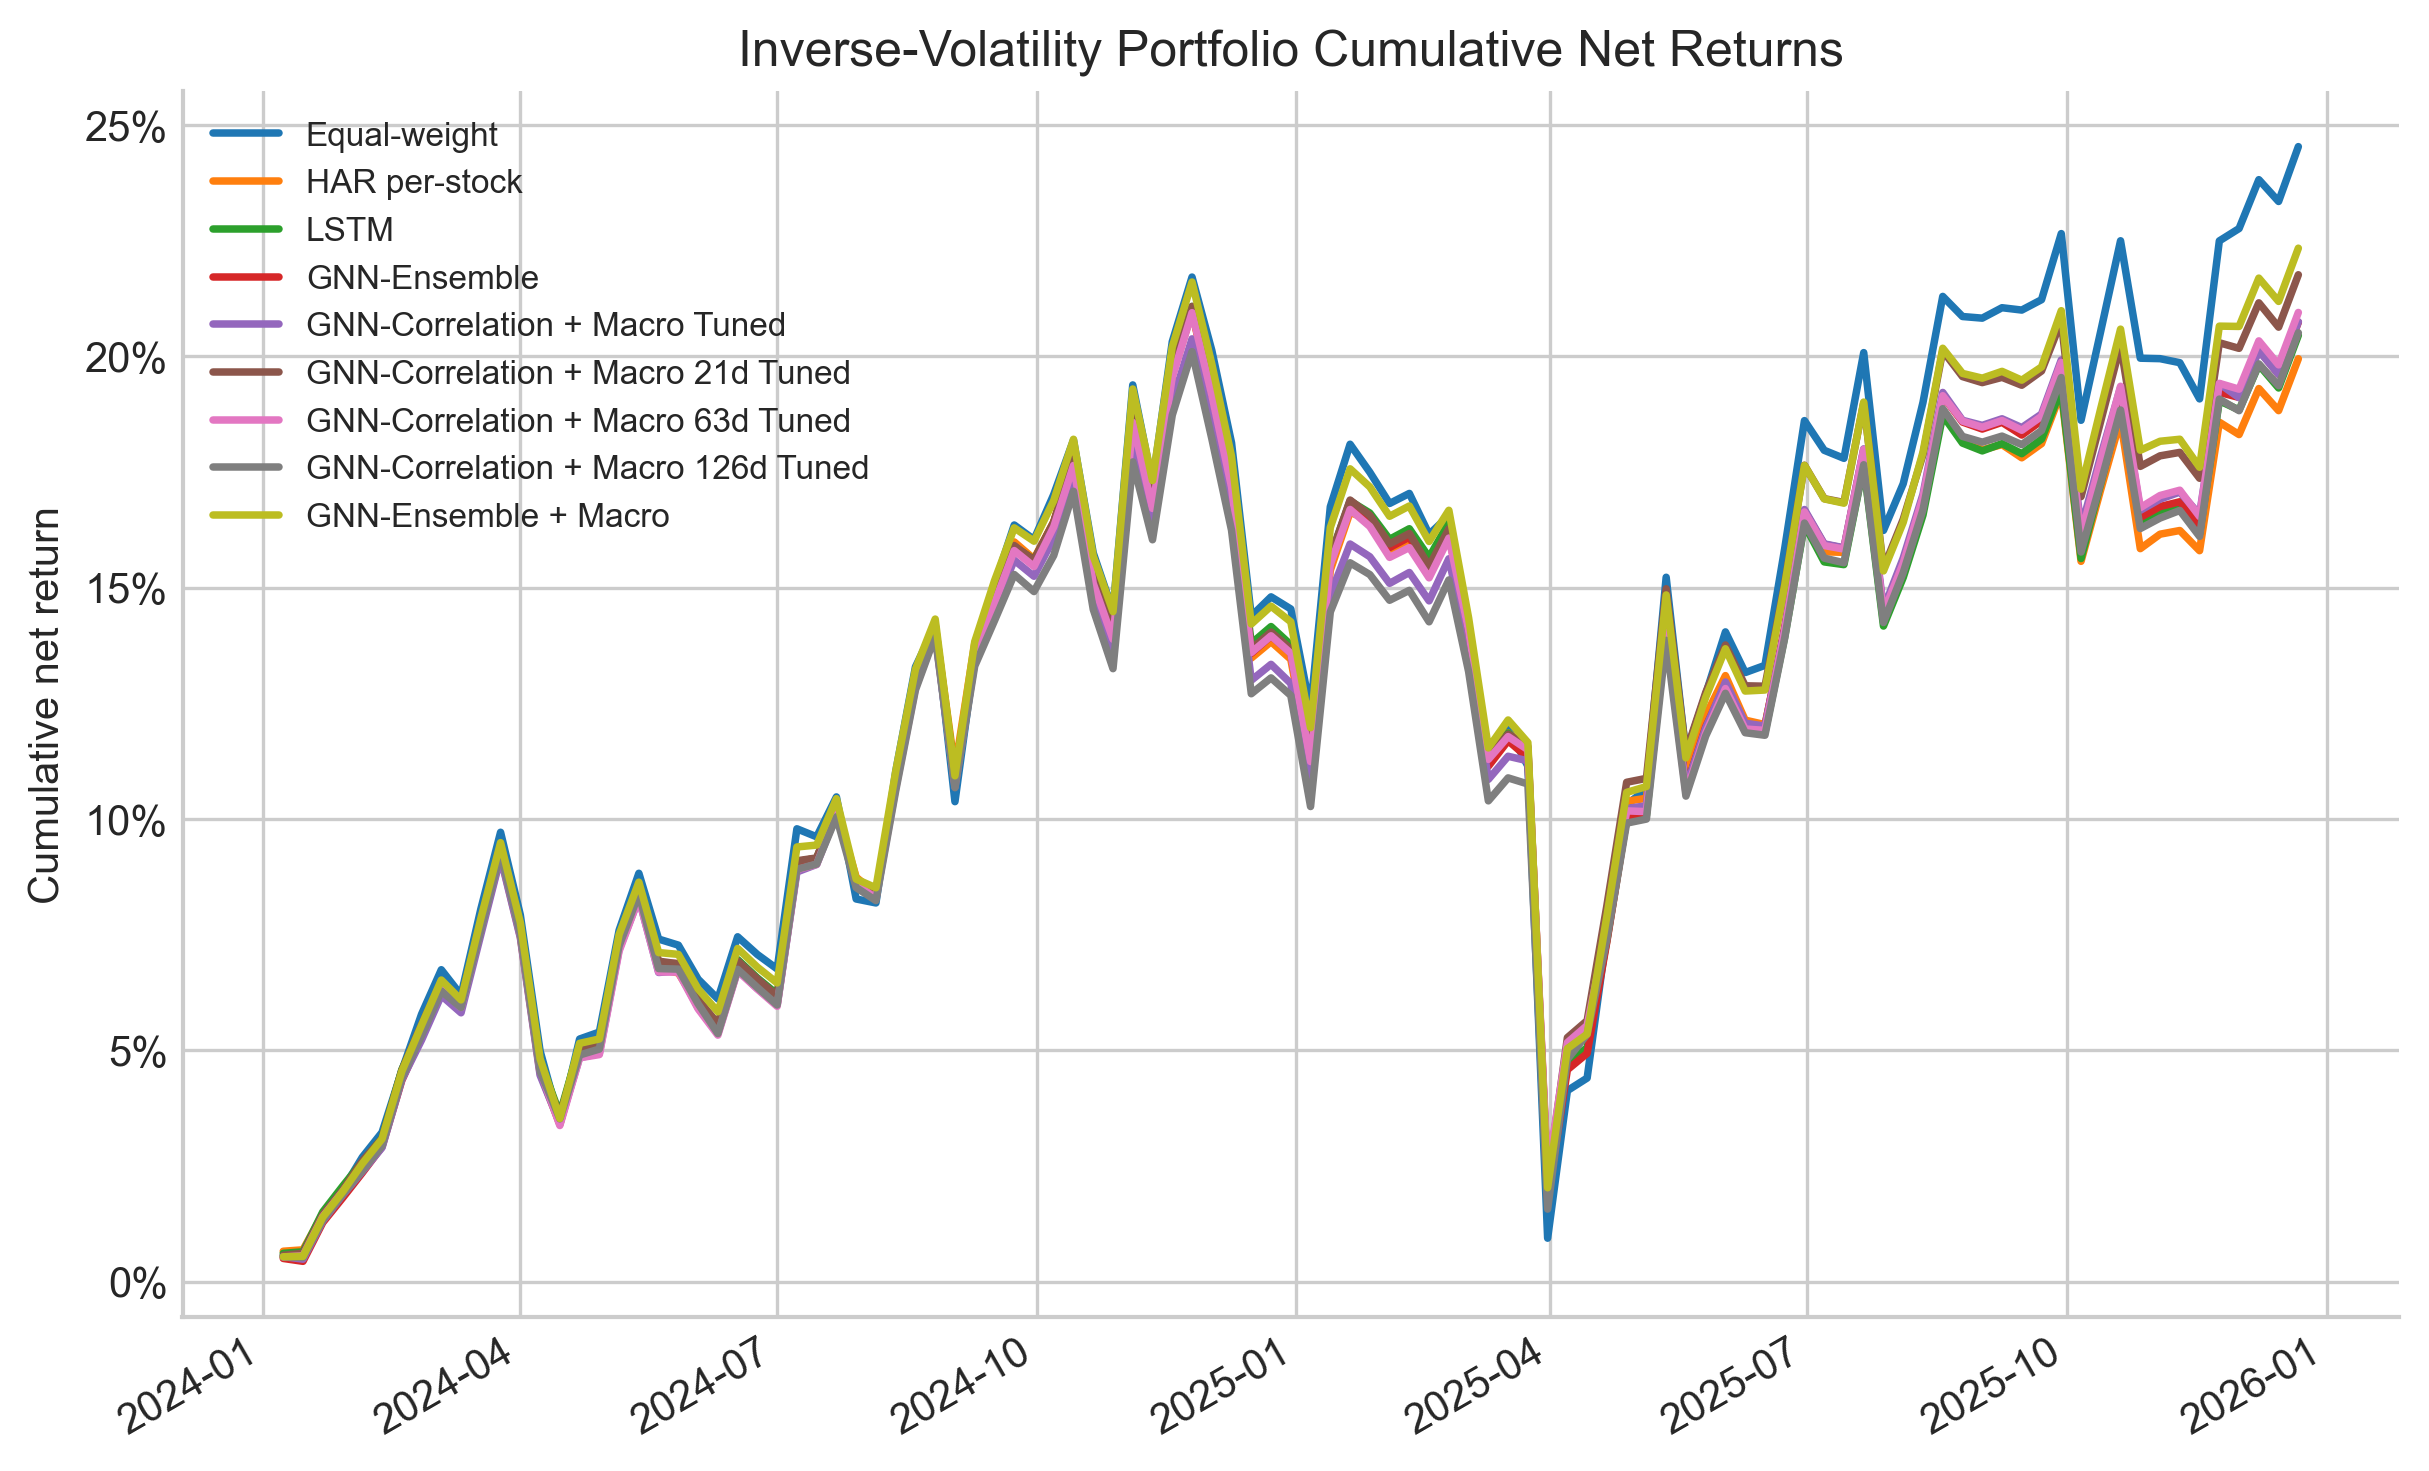

In [9]:
portfolio_tables = {
    "Inverse volatility": RESULTS / "final_portfolio_inverse_vol_metrics.csv",
    "Long short": RESULTS / "final_portfolio_long_short_metrics.csv",
    "Volatility targeted": RESULTS / "final_portfolio_vol_target_metrics.csv",
    "Minimum variance": RESULTS / "final_portfolio_minvar_metrics.csv",
}
for label, path in portfolio_tables.items():
    print(label)
    df = read_csv(path)
    show_table(df, rows=12, sort_by="sharpe" if "sharpe" in df.columns else None, ascending=False)
show_fig("final_portfolio_cumulative_returns.png")